# 03 — Feature Engineering

## Ràng buộc buổi đầu thầy yêu cầu
- **Không sử dụng thư viện scikit-learn** cho phần cài đặt thuật toán chính.
- **Tập test thực tế luôn là tập thô** — không được tiền xử lý hay tham gia vào quá trình fit thông số.
- **Sử dụng các kỹ thuật chống rò rỉ dữ liệu (data leakage prevention)** trong toàn bộ pipeline.

## Giải pháp của nhóm đề ra

| Ràng buộc | Giải pháp |
| :--- | :--- |
| Không dùng scikit-learn | Chỉ sử dụng `scikit-learn` để **so sánh kết quả** . Toàn bộ thuật toán, pipeline tiền xử lý được cài đặt thuần NumPy/Pandas. |
| Tập test thực tế là tập thô | **Split tập thô đầu tiên** (Notebook 01) để chia 2 tập train/test ở dạng thô. Tập test được giữ độc lập hoàn toàn. Nếu cần tập val ở Notebook 04/05 thì split val từ train. |
| Chống rò rỉ dữ liệu | **Chỉ fit tham số duy nhất trên tập train**, xuất ra file `.pkl` để có thể tái sử dụng biến đổi dữ liệu mới trong tương lai một cách nhất quán. Val và test tuyệt đối không tham gia |

---

**Mục tiêu:**
Dựa trên insight từ `02_eda.ipynb`, tạo thêm các đặc trưng mới có ý nghĩa
nghiệp vụ, sau đó **fit** tham số tiền xử lý (Target Statistics + median
fill) **chỉ trên train**, lưu ra `.pkl` để dùng lại nhất quán cho val/test
và cho bước huấn luyện model ở `04_train_model.ipynb` và `05_compare_with_catboost_lib.ipynb`.

> **Nguyên tắc chống rò rỉ dữ liệu (Data Leakage Prevention):**
> Chỉ đọc `train_raw.csv`. `val` không cần thiết ở đây vì chỉ tách val từ train
> khi huấn luyện mô hình ở notebook 04/05. `test_raw.csv` tuyệt đối không được mở ở đây.

**Thứ tự xử lý:**
1. Import / Setup
2. Đọc dữ liệu đã làm sạch từ notebook 01 (`train_raw.csv`)
3. Recap insight từ EDA
4. Hàm `engineer_features()` (src/preprocessing.py)
5. Áp dụng `engineer_features()` cho train
6. Sanity check đặc trưng mới
7. Phân loại cột numerical / categorical
8. **Fit preprocessing params (CHỈ trên train)**
9. Lưu params ra `.pkl`
10. Load lại để kiểm tra round-trip
11. **Transform train**
12. Kiểm tra chất lượng đầu ra (0 NaN trên num_cols, y ∈ {0,1})
13. Đối chiếu Target Statistics với insight EDA
14. Correlation feature sau encode với Churn (baseline riêng)
15. Tính `scale_pos_weight` cho class imbalance
16. Tổng kết (Summary)

## 1 — Import thư viện

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.join('..', 'src'))
from preprocessing import (
    get_feature_lists,
    fit_preprocessing_params,
    transform,
    save_params,
    load_params,
    engineer_features,   # MỚI
    transform_with_target_statistics,  # MỚI -- chỉ dùng riêng cho baseline/
                                        #        phân tích TS (mục 13-14),
                                        #        KHÔNG còn nằm trong transform()
)
import inspect            # MỚI — dùng để hiển thị source code hàm

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})

PROCESSED_DIR = '../data/processed'
FIG_DIR       = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    path = f'{FIG_DIR}/{name}'
    plt.savefig(path, bbox_inches='tight', facecolor='white')
    print(f'  Đã lưu: {path}')

print('Thư viện và hàm từ preprocessing.py đã sẵn sàng.')

Thư viện và hàm từ preprocessing.py đã sẵn sàng.


## 2 — Đọc dữ liệu đã làm sạch từ notebook 01

Chỉ đọc `train_raw.csv`. `test_raw.csv` **KHÔNG được đọc** ở notebook này.
Tập `val` (nếu cần) sẽ được split từ `train` ở Notebook 04/05.

In [2]:
PROCESSED_DIR = '../data/processed'
TRAIN_PATH   = f'{PROCESSED_DIR}/train_raw.csv'

# TEST_PATH KHÔNG được đọc ở notebook này -- xem ghi chú ở trên.
# Tập val (nếu cần) sẽ được split từ train ở Notebook 04/05.

train_df = pd.read_csv(TRAIN_PATH)

print(f'train : {train_df.shape}')
print(f'  train Churn=No : {(train_df["Churn"]=="No").sum():,} dòng')
print(f'  train Churn=Yes: {(train_df["Churn"]=="Yes").sum():,} dòng')

train : (5638, 20)
  train Churn=No : 4,142 dòng
  train Churn=Yes: 1,496 dòng


## 3 — Recap insight từ EDA

Những phát hiện chính từ `02_eda.ipynb` được dùng để dẫn dắt feature
engineering ở bước này:

| # | Insight từ EDA | Áp dụng thế nào ở bước này |
|---|---|---|
| 1 | Churn rate cao nhất ở nhóm **tenure 0-6 tháng** (~47%), giảm dần theo tenure | Tạo `tenure_group` — bin hóa tenure thành đặc trưng categorical, giúp model (và cả các phân tích sau này) bắt rõ bước nhảy theo giai đoạn |
| 2 | Khách hàng **ít dịch vụ tiện ích** (OnlineSecurity/TechSupport...) có xu hướng churn cao hơn | Tạo `num_addon_services` — đếm số dịch vụ tiện ích đang sử dụng |
| 3 | `tenure` và `TotalCharges` tương quan mạnh (**r ~ 0.83**) — đa cộng tuyến | Tạo `avg_monthly_spend` = TotalCharges / tenure để chuẩn hóa quy mô chi tiêu, giảm lệ thuộc trực tiếp vào độ dài hợp đồng |
| 4 | Mất cân bằng lớp **~73.5% No / ~26.5% Yes** (~2.7 : 1) | Tính `scale_pos_weight` ở cuối notebook này, dùng làm tham số cho `04_train_model.ipynb` |
| 5 | 15 cột categorical, dirty data đã được chuẩn hóa ở notebook 01 | Encode toàn bộ categorical bằng **Target Statistics** (hàm có sẵn trong `preprocessing.py`) thay vì one-hot — đúng phong cách CatBoost, tránh nổ dimension |
| 6 | `Contract`, `InternetService`, `OnlineSecurity` là các cột liên quan mạnh nhất đến Churn | Kiểm tra lại TS mapping của chính các cột này ở mục 12 để xác nhận hướng tương quan đúng như EDA |

> Lưu ý: các đặc trưng mới ở bước này (`tenure_group`, `num_addon_services`,
> `avg_monthly_spend`) đều là **phép biến đổi thuần túy theo từng dòng**
> (row-wise), không học tham số nào từ dữ liệu -> an toàn áp dụng giống hệt
> nhau cho cả train/val/test, không gây leakage.

## 4 — Hàm `engineer_features()` (định nghĩa trong src/preprocessing.py)

Hàm này đã được chuyển sang `src/preprocessing.py` (không còn định nghĩa lại
ở đây) để dùng lại được nguyên vẹn ở `04_train_model.ipynb` khi transform
`test_raw.csv` lúc predict — tránh copy-paste code và bị lệch logic giữa
train/val/test.

Hàm thuần túy (không fit), nhận vào 1 DataFrame và trả về DataFrame có
thêm 3 cột mới. Vì không học tham số từ dữ liệu nên gọi được an toàn cho
cả train / val / test mà không cần "fit" riêng.

Cell bên dưới import hàm này từ preprocessing.py và in source code ra để
vẫn xem được toàn bộ logic ngay trong notebook, không cần mở file khác.

In [3]:
# Hàm engineer_features() giờ nằm trong src/preprocessing.py để dùng
# chung được với 04_train_model.ipynb khi transform test_raw.csv lúc
# predict -- tránh copy-paste code và bị lệch logic giữa train/val/test.
# In source code ra đây để vẫn xem được toàn bộ logic ngay trong notebook:
print(inspect.getsource(engineer_features))

def engineer_features(df: pd.DataFrame) -> pd.DataFrame:

    df = df.copy()

    # 1. tenure_group
    bins   = [-0.1, 6, 12, 24, 36, 48, 60, 100]
    labels = ['0-6', '7-12', '13-24', '25-36', '37-48', '49-60', '61+']
    df['tenure_group'] = pd.cut(df['tenure'], bins=bins, labels=labels).astype(str)
    df.loc[df['tenure'].isna(), 'tenure_group'] = np.nan

    # 2. num_addon_services
    addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                  'TechSupport', 'StreamingTV', 'StreamingMovies']
    df['num_addon_services'] = (df[addon_cols] == 'Yes').sum(axis=1)

    # 3. avg_monthly_spend (fallback = MonthlyCharges khi tenure = 0)
    safe_tenure = df['tenure'].replace(0, np.nan)
    avg_spend   = df['TotalCharges'] / safe_tenure
    df['avg_monthly_spend'] = avg_spend.fillna(df['MonthlyCharges'])

    return df



## 5 — Áp dụng `engineer_features()` cho train

Tạo 3 đặc trưng mới cho tập `train_df`:
- `tenure_group`: nhóm thời gian gắn bó (binned tenure).
- `num_addon_services`: số dịch vụ gia tăng đã đăng ký (0-6).
- `avg_monthly_spend`: chi tiêu trung bình thực tế mỗi tháng.

In [4]:
train_fe = engineer_features(train_df)

print('Shape sau feature engineering:')
print(f'  train_fe: {train_fe.shape}')
print(f'Số feature mới: 3 (từ {train_df.shape[1]} -> {train_fe.shape[1]} cột)')

Shape sau feature engineering:
  train_fe: (5638, 23)
Số feature mới: 3 (từ 20 -> 23 cột)


## 6 — Sanity check đặc trưng mới

Kiểm tra nhanh giá trị các cột mới có hợp lý không trước khi đưa vào fit.

In [5]:
print('tenure_group value_counts (train):')
print(train_fe['tenure_group'].value_counts().sort_index())

print('\nnum_addon_services value_counts (train):')
print(train_fe['num_addon_services'].value_counts().sort_index())

print('\navg_monthly_spend describe (train):')
print(train_fe['avg_monthly_spend'].describe())

# Assert cơ bản
assert train_fe['tenure_group'].isna().sum() == train_fe['tenure'].isna().sum(), \
    'FAIL: tenure_group NaN không khớp với tenure NaN'
assert train_fe['num_addon_services'].between(0, 6).all(), \
    'FAIL: num_addon_services phải trong khoảng [0, 6]'
assert train_fe['avg_monthly_spend'].isna().sum() == 0, \
    'FAIL: avg_monthly_spend không được có NaN (đã có fallback)'
print('\nASSERT: 3 đặc trưng mới hợp lệ: PASS')

tenure_group value_counts (train):
tenure_group
0-6      1195
13-24     818
25-36     692
37-48     598
49-60     669
61+      1089
7-12      577
Name: count, dtype: int64

num_addon_services value_counts (train):
num_addon_services
0    1759
1     812
2     820
3     891
4     672
5     462
6     222
Name: count, dtype: int64

avg_monthly_spend describe (train):
count    5638.000000
mean       64.771070
std        30.076983
min         0.000000
25%        37.071875
50%        70.219345
75%        89.917580
max       121.400000
Name: avg_monthly_spend, dtype: float64

ASSERT: 3 đặc trưng mới hợp lệ: PASS


## 7 — Phân loại cột numerical / categorical

Dùng `get_feature_lists()` có sẵn trong `preprocessing.py` — tự động
phân loại theo dtype, loại bỏ cột target (`Churn`). Hàm này sẽ được gọi
lại bên trong `fit_preprocessing_params()` ở mục 8, ở đây chỉ gọi trước
để xem trước danh sách.

In [6]:
num_cols, cat_cols = get_feature_lists(train_fe, target_col='Churn', exclude_cols=[])

print(f'Numerical  ({len(num_cols)} cột): {num_cols}')
print(f'\nCategorical ({len(cat_cols)} cột):')
for i, c in enumerate(cat_cols, 1):
    tag = '  <-- MỚI' if c == 'tenure_group' else ''
    print(f'  [{i:02d}] {c}{tag}')

Numerical  (6 cột): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_addon_services', 'avg_monthly_spend']

Categorical (16 cột):
  [01] gender
  [02] Partner
  [03] Dependents
  [04] PhoneService
  [05] MultipleLines
  [06] InternetService
  [07] OnlineSecurity
  [08] OnlineBackup
  [09] DeviceProtection
  [10] TechSupport
  [11] StreamingTV
  [12] StreamingMovies
  [13] Contract
  [14] PaperlessBilling
  [15] PaymentMethod
  [16] tenure_group  <-- MỚI


## 8 — Fit preprocessing params (CHỈ trên train)

Gọi `fit_preprocessing_params()` — hàm tổng hợp trong `preprocessing.py`,
bên trong nó thực hiện:
1. `clean_total_charges()` — idempotent, TotalCharges đã sạch từ trước.
2. `get_feature_lists()` — phân loại num/cat.
3. `fit_missing_value_params()` — tính median các cột numerical **trên train**.
4. `fit_target_statistics()` — tính Target Statistics các cột categorical
   **trên train**, smoothing = 1.0 (Laplace smoothing).

**Chỉ gọi hàm này 1 lần duy nhất, với `train_fe`.**

In [7]:
SMOOTHING = 1.0

params = fit_preprocessing_params(
    train_fe,
    target_col='Churn',
    exclude_cols=[],       # customerID đã không còn trong data
    smoothing=SMOOTHING,
)

print('Các key trong params:', list(params.keys()))
print(f"\nSố cột numerical : {len(params['num_cols'])}")
print(f"Số cột categorical: {len(params['cat_cols'])}")
print(f"Global mean (tỷ lệ Churn=Yes trên train): {params['ts_params']['global_mean']:.4f}")
print(f"Smoothing: {params['ts_params']['smoothing']}")

Các key trong params: ['target_col', 'exclude_cols', 'num_cols', 'cat_cols', 'fill_params', 'ts_params']

Số cột numerical : 6
Số cột categorical: 16
Global mean (tỷ lệ Churn=Yes trên train): 0.2653
Smoothing: 1.0


## 9 — Lưu params ra `.pkl`

In [8]:
PARAMS_PATH = f'{PROCESSED_DIR}/preprocessing_params.pkl'
save_params(params, PARAMS_PATH)

[OK] Da luu params: preprocessing_params.pkl  (1.6 KB)


## 10 — Load lại để kiểm tra round-trip

Đảm bảo file `.pkl` đọc lại được đúng ý như lúc lưu — đây là file sẽ
được `04_train_model.ipynb` load để transform dữ liệu khi train model.

In [9]:
params_loaded = load_params(PARAMS_PATH)

assert params_loaded['num_cols'] == params['num_cols']
assert params_loaded['cat_cols'] == params['cat_cols']
assert params_loaded['ts_params']['global_mean'] == params['ts_params']['global_mean']
print('\nASSERT: params đọc lại từ file .pkl khớp 100% với params vừa fit: PASS')

[OK] Da tai params: preprocessing_params.pkl
     Cac key: ['target_col', 'exclude_cols', 'num_cols', 'cat_cols', 'fill_params', 'ts_params']

ASSERT: params đọc lại từ file .pkl khớp 100% với params vừa fit: PASS


## 11 — Transform train

Áp dụng `transform()` với `params_loaded`:
- `TotalCharges`: clean và ép kiểu `float64`.
- `fill_params`: điền NaN numerical bằng median đã fit từ train.
- `cat_cols`: giữ nguyên dạng thô (string) cho model CatBoost tự xử lý nội bộ.
- `y`: map về `{0.0, 1.0}`.

In [10]:
X_train, y_train = transform(train_fe, params_loaded)

print('Shape sau transform:')
print(f'  X_train: {X_train.shape}   y_train: {y_train.shape}')

print(f'\nSố cột feature cuối cùng: {X_train.shape[1]} ' \
      f'(= {len(params["num_cols"])} numerical + {len(params["cat_cols"])} categorical)')

Shape sau transform:
  X_train: (5638, 22)   y_train: (5638,)

Số cột feature cuối cùng: 22 (= 6 numerical + 16 categorical)


## 12 — Kiểm tra chất lượng đầu ra

Đảm bảo **num_cols** không còn NaN (điều kiện bắt buộc trước khi đưa vào
model). **cat_cols** giữ dạng thô nên có thể còn NaN — chỉ báo cáo số
lượng, không assert bằng 0 (model CatBoost tự xử lý NaN categorical).
`y` chỉ còn 2 giá trị {0.0, 1.0}.

In [11]:
num_cols = params_loaded['num_cols']
cat_cols = params_loaded['cat_cols']

n_nan_num = int(X_train[num_cols].isna().sum().sum())
n_nan_cat = int(X_train[cat_cols].isna().sum().sum())
assert n_nan_num == 0, f'FAIL: X_train[num_cols] còn {n_nan_num} giá trị NaN'
print(f'  X_train : num_cols NaN = {n_nan_num} (assert == 0)   '
      f'cat_cols NaN = {n_nan_cat} (info, cho phép > 0)')
print(f'           dtype toàn bộ: {sorted(set(str(t) for t in X_train.dtypes))}')

vals = set(y_train.dropna().unique().tolist())
assert vals <= {0.0, 1.0}, f'FAIL: y_train có giá trị lạ {vals}'
print(f'  y_train : unique = {sorted(vals)}')

print('\nASSERT: X[num_cols] không NaN, y chỉ có {0.0, 1.0}: PASS')
print('(X[cat_cols] giữ dạng thô, có thể còn NaN -- model tự xử lý)')
print('(test_raw.csv vẫn giữ nguyên dạng thô, chưa được đụng đến)')
print('(val sẽ được split từ train tại Notebook 04/05 nếu cần)')

print('\n5 dòng đầu X_train:')
X_train.head()

  X_train : num_cols NaN = 0 (assert == 0)   cat_cols NaN = 2 (info, cho phép > 0)
           dtype toàn bộ: ['float64', 'int64', 'str']
  y_train : unique = [0.0, 1.0]

ASSERT: X[num_cols] không NaN, y chỉ có {0.0, 1.0}: PASS
(X[cat_cols] giữ dạng thô, có thể còn NaN -- model tự xử lý)
(test_raw.csv vẫn giữ nguyên dạng thô, chưa được đụng đến)
(val sẽ được split từ train tại Notebook 04/05 nếu cần)

5 dòng đầu X_train:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,num_addon_services,avg_monthly_spend,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,tenure_group
0,0,19.0,60.60,1297.80,3,68.305263,Female,No,Yes,Yes,No,DSL,Yes,Yes,Yes,No,No,No,Month-to-month,Yes,Electronic check,13-24
1,0,32.0,20.35,707.50,0,22.109375,Male,No,No,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Credit card (automatic),25-36
2,0,1.0,43.95,43.95,0,43.950000,Female,No,No,Yes,No,DSL,No,No,No,No,No,No,Month-to-month,No,Credit card (automatic),0-6
3,0,46.0,30.30,1380.10,1,30.002174,Male,No,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,No,Bank transfer (automatic),37-48
4,0,22.0,19.95,433.50,0,19.704545,Male,Yes,Yes,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,No,Mailed check,13-24


## 13 — Đối chiếu Target Statistics với churn rate quan sát ở EDA

`02_eda.ipynb` chỉ ra `Contract`, `InternetService`, `OnlineSecurity` là
các cột liên quan mạnh nhất đến Churn. Kiểm tra lại: TS mapping (giá trị
float sau encode) có phản ánh đúng thứ tự churn rate quan sát được không
— TS càng cao nghĩa là nhóm đó có tỷ lệ Churn=Yes càng cao.

In [12]:
check_cols = ['Contract', 'InternetService', 'OnlineSecurity', 'tenure_group']

for col in check_cols:
    ts_map = params_loaded['ts_params']['mappings'][col]
    print(f'[{col}]  Target Statistics (sắp xếp giảm dần):')
    for cat, ts_val in sorted(ts_map.items(), key=lambda kv: -kv[1]):
        n = int((train_fe[col].astype(str) == cat).sum())
        print(f'    {cat:<20s}: TS = {ts_val:.4f}   (n = {n} dòng trong train)')
    print()

[Contract]  Target Statistics (sắp xếp giảm dần):
    Month-to-month      : TS = 0.4257   (n = 3126 dòng trong train)
    One year            : TS = 0.1057   (n = 1184 dòng trong train)
    Two year            : TS = 0.0303   (n = 1328 dòng trong train)

[InternetService]  Target Statistics (sắp xếp giảm dần):
    Fiber optic         : TS = 0.4213   (n = 2480 dòng trong train)
    DSL                 : TS = 0.1843   (n = 1954 dòng trong train)
    No                  : TS = 0.0757   (n = 1204 dòng trong train)

[OnlineSecurity]  Target Statistics (sắp xếp giảm dần):
    No                  : TS = 0.4153   (n = 2805 dòng trong train)
    Yes                 : TS = 0.1474   (n = 1629 dòng trong train)
    No internet service : TS = 0.0757   (n = 1204 dòng trong train)

[tenure_group]  Target Statistics (sắp xếp giảm dần):
    0-6                 : TS = 0.5328   (n = 1195 dòng trong train)
    7-12                : TS = 0.3534   (n = 577 dòng trong train)
    13-24               : TS = 0.

## 14 — Correlation toàn bộ feature (sau encode TS) với Churn — BASELINE RIÊNG

Khác với `02_eda.ipynb` (chỉ tính correlation trên 3 cột numerical gốc),
ở đây tính trên toàn bộ feature **sau khi encode bằng Target Statistics**
— nhưng đây CHỈ là một phép phân tích baseline độc lập, dùng
`transform_with_target_statistics()` trên một bản sao riêng, KHÔNG dùng
`X_train` (X_train từ mục 11 giờ giữ categorical dạng thô, không còn TS).

Mục đích: xem trước feature nào có thể mạnh nếu dùng TS-encoding làm
baseline so sánh với cách CatBoost tự xử lý categorical ở 04/05 — không
phải bước bắt buộc của pipeline chính.

  Đã lưu: ../reports/figures/feature_correlation_ts_baseline.png


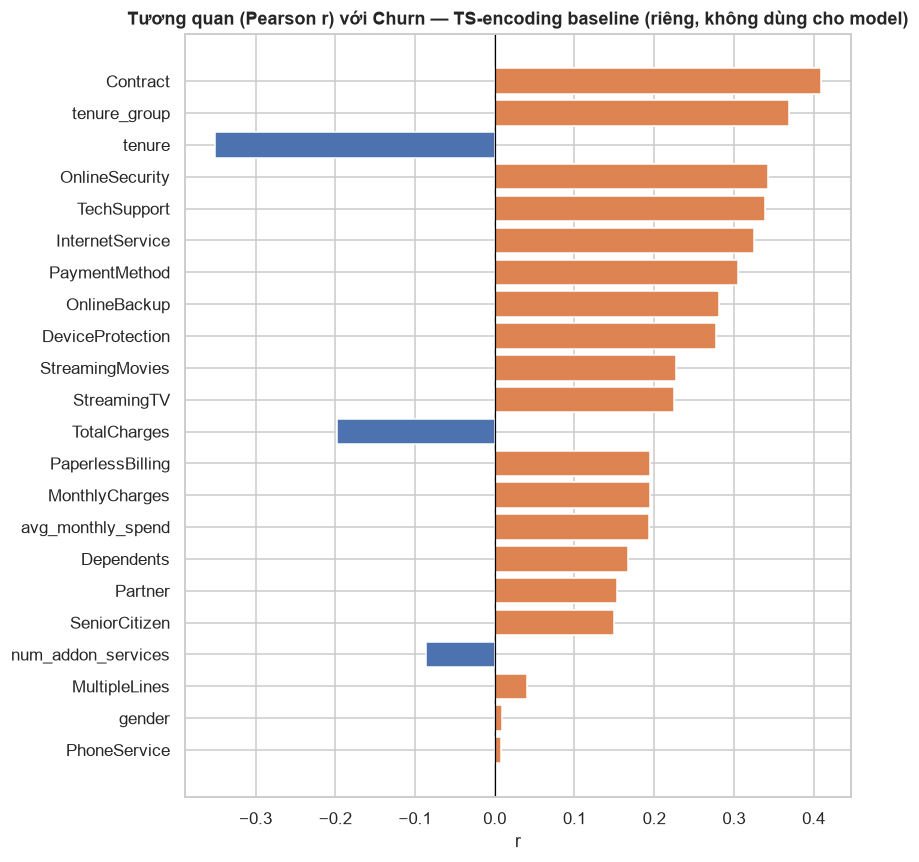

Top 8 feature liên quan mạnh nhất đến Churn (theo TS baseline):
  Contract            : r = +0.4094
  tenure_group        : r = +0.3685  <-- đặc trưng MỚI
  tenure              : r = -0.3511
  OnlineSecurity      : r = +0.3428
  TechSupport         : r = +0.3391
  InternetService     : r = +0.3257
  PaymentMethod       : r = +0.3048
  OnlineBackup        : r = +0.2819


In [13]:
# Baseline TS-encoding RIÊNG cho mục đích phân tích correlation --
# KHÔNG ảnh hưởng X_train/X_val dùng cho model ở 04/05.
train_ts_baseline = transform_with_target_statistics(
    train_fe, params_loaded['ts_params'], cat_cols
)

corr_df = train_ts_baseline[num_cols + cat_cols].copy()
corr_df['Churn'] = y_train
corr_with_churn = (corr_df.corr()['Churn']
                   .drop('Churn')
                   .sort_values(key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(8, 8))
colors = ['#DD8452' if v > 0 else '#4C72B0' for v in corr_with_churn.values]
ax.barh(corr_with_churn.index[::-1], corr_with_churn.values[::-1],
        color=colors[::-1], edgecolor='white')
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Tương quan (Pearson r) với Churn — TS-encoding baseline (riêng, không dùng cho model)',
             fontweight='bold')
ax.set_xlabel('r')
plt.tight_layout()
savefig('feature_correlation_ts_baseline.png')
plt.show()

print('Top 8 feature liên quan mạnh nhất đến Churn (theo TS baseline):')
for feat, r in corr_with_churn.head(8).items():
    tag = '  <-- đặc trưng MỚI' if feat in ['tenure_group', 'num_addon_services',
                                             'avg_monthly_spend'] else ''
    print(f'  {feat:<20s}: r = {r:+.4f}{tag}')

## 15 — Mất cân bằng lớp: tính `scale_pos_weight`

EDA ghi nhận mất cân bằng lớp ~2.7:1 (No:Yes) và đề xuất dùng
`class_weights`/`scale_pos_weight`. Tính giá trị này trên **train** để
`04_train_model.ipynb` dùng làm tham số khởi tạo model — KHÔNG tính trên
val/test vì đây là thông tin thuộc về quá trình huấn luyện.

In [14]:
n_neg = int((y_train == 0.0).sum())
n_pos = int((y_train == 1.0).sum())
scale_pos_weight = n_neg / n_pos

print(f'Train — Churn=No (0): {n_neg:,} dòng')
print(f'Train — Churn=Yes(1): {n_pos:,} dòng')
print(f'Tỷ lệ No:Yes        : {scale_pos_weight:.3f} : 1')
print(f'\n-> scale_pos_weight đề xuất cho 04_train_model.ipynb: {scale_pos_weight:.4f}')

Train — Churn=No (0): 4,142 dòng
Train — Churn=Yes(1): 1,496 dòng
Tỷ lệ No:Yes        : 2.769 : 1

-> scale_pos_weight đề xuất cho 04_train_model.ipynb: 2.7687


## 16 — Tổng kết (Summary)

Tổng kết toàn bộ những gì đã thực hiện trong notebook `03_feature_engineering.ipynb`.

In [15]:
print('  TỔNG KẾT -- 03_feature_engineering.ipynb')

new_cols = ['tenure_group', 'num_addon_services', 'avg_monthly_spend']
print(f'\n Đặc trưng mới đã thêm (dựa trên insight EDA):')
for c in new_cols:
    print(f'   - {c}')

print(f'\n Phân loại feature cuối cùng:')
print(f'   Numerical   ({len(params["num_cols"])} cột): {params["num_cols"]}')
print(f'   Categorical ({len(params["cat_cols"])} cột): {params["cat_cols"]}')

print(f'\n Tham số đã fit (CHỈ trên train, {len(train_fe):,} dòng):')
print(f'   Smoothing (Target Statistics) : {SMOOTHING}')
print(f'   Global mean (tỷ lệ Churn=Yes)  : {params["ts_params"]["global_mean"]:.4f}')
print(f'   Đã fit median cho {len(params["fill_params"])} cột numerical')
print(f'   Đã fit Target Statistics cho {len(params["ts_params"]["mappings"])} cột categorical')

print(f'\n File đã lưu: {PARAMS_PATH}')
print(f'   Size: {os.path.getsize(PARAMS_PATH)/1024:.1f} KB')

print(f'\n Shape feature matrix sau transform:')
print(f'   X_train: {X_train.shape}')
print(f'   num_cols: 0 NaN (assert). cat_cols: giữ dạng thô, có thể còn NaN')
print(f'   (model CatBoost tự xử lý). Sẵn sàng đưa vào model.')
print(f'   test_raw.csv: CHƯA được đụng đến, vẫn giữ nguyên dạng thô.')
print(f'   val: sẽ được split từ train ở NB 04/05 nếu cần.')

print(f'\n scale_pos_weight đề xuất cho model: {scale_pos_weight:.4f}')

print(f'\n Top 3 feature liên quan mạnh nhất đến Churn:')
for feat, r in corr_with_churn.head(3).items():
    print(f'   {feat:<20s}: r = {r:+.4f}')

print('\n Bước tiếp theo: notebook 04_train_model.ipynb')
print('-> đọc test_raw.csv (lần đầu tiên và DUY NHẤT đụng đến test)')
print('-> tách val từ train nếu cần validation')
print(f"-> load_params('{PARAMS_PATH}')")
print('-> from preprocessing import engineer_features, transform')

  TỔNG KẾT -- 03_feature_engineering.ipynb

 Đặc trưng mới đã thêm (dựa trên insight EDA):
   - tenure_group
   - num_addon_services
   - avg_monthly_spend

 Phân loại feature cuối cùng:
   Numerical   (6 cột): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'num_addon_services', 'avg_monthly_spend']
   Categorical (16 cột): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']

 Tham số đã fit (CHỈ trên train, 5,638 dòng):
   Smoothing (Target Statistics) : 1.0
   Global mean (tỷ lệ Churn=Yes)  : 0.2653
   Đã fit median cho 6 cột numerical
   Đã fit Target Statistics cho 16 cột categorical

 File đã lưu: ../data/processed/preprocessing_params.pkl
   Size: 1.6 KB

 Shape feature matrix sau transform:
   X_train: (5638, 22)
   num_cols: 0 NaN (assert). cat_cols: giữ dạng thô